# Three curve forms around one mean size: Rosin-Rammler, Swebrec and the crush-zone composition, and the cap at the in situ block

**Question:** Do the three curve forms agree once the mean size is fixed, and what does the block cap change?

**Level 2: The method in practice** · Needs: 03-size-distribution/01-from-a-mean-size-to-a-curve · Reading time: about 35 minutes

## Objectives

Rosin-Rammler has two known weaknesses: it underestimates the fines and it has no upper size limit. The engine carries two more curve forms and a structural cap against them. This notebook builds each one on a single blast, repeats the comparison on every blast with a geometry, and measures what the cap does to the one quantity the corpus records.

By the end you will have:

- built the Rosin-Rammler, Swebrec and crush-zone curves of the Enusa blast from their parameters and read what each one adds;
- compared the P20 and the P80 of the three forms on 91 blasts, each against its own mean size;
- swept the Swebrec undulation and seen where it moves the fines and the coarse end;
- applied the cap at the in situ block and scored the capped and uncapped mean size against the measurements.

## Setup

Install the packages with the exact pins of `notebooks/requirements.txt`. The engine is `blastfrag`, published on PyPI; the other packages are its numerical base and the plotting library.

```bash
pip install blastfrag==0.4.0 numpy==2.5.4 matplotlib==3.11.2
```

One cell does all the preparation: it imports the packages, prints their installed versions so the output records which engine produced every number below, defines the table helper and loads the 97 training blasts.

In [1]:
# Imports, the versions behind every number below, a small table helper and the corpus
import json
from importlib.metadata import version
from pathlib import Path

import blastfrag as bf
import matplotlib.pyplot as plt
import numpy as np
from IPython.display import HTML, display

for name in ("blastfrag", "numpy", "matplotlib"):
    print(f"{name}=={version(name)}")


def show_table(columns, rows):
    # pandas is not part of the notebook environment, so a table is a plain HTML table
    head = "".join(f"<th>{c}</th>" for c in columns)
    body = "".join("<tr>" + "".join(f"<td>{v}</td>" for v in row) + "</tr>" for row in rows)
    display(HTML(f"<table><thead><tr>{head}</tr></thead><tbody>{body}</tbody></table>"))


CASE = Path("../../../data/derived/real-enusa/case.json")
train = bf.load_training_corpus()

blastfrag==0.4.0
numpy==2.5.4
matplotlib==3.11.2


## Data

| Source | Owner and URL | Licence class | File the notebook reads |
|---|---|---|---|
| The corpus and the reconstructed patterns | Hudaverdi, Kulatilake and Kuzu 2010, https://doi.org/10.1002/nag.957 | numeric facts reused with citation; the article never ships | the corpus inside the `blastfrag` wheel |
| The Swebrec function | Ouchterlony 2005, https://doi.org/10.1179/037178405x44539, as printed in Amoako, Jha and Zhong 2022, https://doi.org/10.3390/mining2020013 (Eqs. 10 and 11) | the equation is reproduced with citation | `bf.swebrec` |
| The counter-example for Swebrec | Babaeian et al. 2019, https://doi.org/10.1016/j.jrmge.2018.11.006 | cited only | none (a statement in the engine's own docstring) |
| The Enusa case, to name its representative blast | this repository (MIT), written by the offline bake | the product's own licence | `data/derived/real-enusa/case.json`, field `representative_blast_id` |

No measured size distribution exists in the corpus: only the mean size of each blast is measured. The three curve forms are model output, and the notebook compares them with each other and with that one measured quantity.

## Method

**Rosin-Rammler** (Amoako, Jha and Zhong 2022, Eq. 5) is the two-parameter curve of the previous notebook. **Swebrec** (Ouchterlony 2005, as printed in Amoako et al. 2022, Eqs. 10 and 11) has three parameters:

```
P(x) = 1 / (1 + f(x)),   f(x) = [ ln(x_max / x) / ln(x_max / x50) ]^b
```

The upper limit `x_max` fixes the coarse tail (the engine takes the larger of burden and spacing) and the undulation `b` shapes the fines. Amoako et al. state that the function "is able to predict fines better"; the engine ships a counter-example next to it, because Babaeian et al. 2019 found Rosin-Rammler closer to image analysis at a bauxite mine, so Swebrec is not presented as better everywhere.

**Crush-zone composition.** Two failure modes act at once: tensile fracture gives the coarse fragments and compressive-shear fracture around the hole gives the fines. The engine blends a coarse Rosin-Rammler branch with a second, finer branch by mass. The structure is sourced from Amoako et al. 2022, but its three constants (crossover size, fines uniformity and fines fraction) are not published in any source held for this work, so they are plausible starting values and every result says so.

**Cap at the in situ block.** A blast breaks blocks and does not fuse them, so mass a curve places above the in situ block size `XB` is read as unbroken blocks at `XB`: `P_cap(x) = P(x)` below `XB` and 1 from `XB` up. This is a declared modelling choice of the engine, not a published relation. What to look for: whether the three forms differ at the middle or at the tails, which parameter moves what, and whether the cap improves the one number that can be checked.

### Step 1: the blast and the parameters of each form

The cell takes the representative blast of the Enusa case, asks the classical equation for its mean size and the pattern for its uniformity index, and collects every parameter the three curve forms need. The table is the contract of the comparison: all three forms share the same `x50`, and each adds only what its row lists.

In [2]:
# The representative Enusa blast, its classical mean size and the parameters each curve form takes
blast_id = json.loads(CASE.read_text(encoding="utf-8"))["representative_blast_id"]
blast = next(b for b in train if b.blast_id == blast_id)
pattern = bf.reconstruct_pattern(blast)
x50 = bf.Kuznetsov().predict_one(blast).x50_m
n_index = bf.cunningham_uniformity_index(pattern)
x_max = max(pattern.burden_m, pattern.spacing_m)
undulation = bf.Swebrec().undulation
crush = bf.classical.CrushZoneParameters()

rows = [
    ("all three", "mean size x50", f"{x50:.4f} m"),
    ("Rosin-Rammler", "uniformity index n", f"{n_index:.4f}"),
    ("Swebrec", "upper size x_max (larger of B and S)", f"{x_max:.3f} m"),
    ("Swebrec", "undulation b, engine default", f"{undulation}"),
    ("crush zone", "crossover size", f"{crush.crossover_m} m"),
    ("crush zone", "fines uniformity", f"{crush.fines_uniformity}"),
    ("crush zone", "fines fraction", f"{crush.fines_fraction}"),
    ("blast", "in situ block XB", f"{blast.XB_m} m"),
]
show_table(["curve form", "parameter", "value"], rows)

curve form,parameter,value
all three,mean size x50,0.4399 m
Rosin-Rammler,uniformity index n,0.6321
Swebrec,upper size x_max (larger of B and S),5.579 m
Swebrec,"undulation b, engine default",2.0
crush zone,crossover size,0.01 m
crush zone,fines uniformity,0.8
crush zone,fines fraction,0.05
blast,in situ block XB,0.58 m


All three forms start from the same mean size of 0.4399 m, and each adds only what its rows list. Swebrec's upper limit is 5.579 m, the spacing, which is far above the in situ block of 0.58 m: the block is the physical ceiling of a fragment, and this parameter is not. The crush-zone constants (a crossover at 0.01 m, a fines uniformity of 0.8 and a fines fraction of 0.05) are the engine's starting values and not published numbers, which step 4 prints as a flag. The table does not say which values are right for this rock; it only fixes what the comparison below varies.

### Step 2: Rosin-Rammler

`rosin_rammler` takes the mean size and the index. The cell builds the curve, prints how much of the mass it leaves passing at the last size of the sieve grid and at the in situ block, and reads the three percentiles. These two checks are what the other forms are meant to improve.

In [3]:
# Curve 1, Rosin-Rammler: two parameters, and the sizes it implies
rosin = bf.rosin_rammler(x50, n_index)
size_top = rosin.sizes_m[-1]
print(f"Rosin-Rammler passing at the grid's last size ({size_top:.1f} m): {rosin.passing[-1]:.3f}")
print(f"Rosin-Rammler passing at the in situ block ({blast.XB_m} m): {rosin.passing_at(blast.XB_m):.3f}")
show_table(["P20 (m)", "P50 (m)", "P80 (m)"], [[f"{rosin.percentile_m(f):.4f}" for f in (0.2, 0.5, 0.8)]])

Rosin-Rammler passing at the grid's last size (3.0 m): 0.903
Rosin-Rammler passing at the in situ block (0.58 m): 0.562


P20 (m),P50 (m),P80 (m)
0.0732,0.4399,1.6679


Rosin-Rammler reaches only 0.903 of the mass at the 3.0 m end of the grid, so about a tenth of the blasted rock is placed in pieces larger than the largest sieve, and it leaves 0.562 of the mass below the in situ block of 0.58 m, so the rest of it sits above a size the rock cannot exceed. Its P20, P50 and P80 are 0.0732 m, 0.4399 m and 1.6679 m. These are the figures the other two forms are meant to correct; they do not show how wrong they are, because there is no measured distribution to compare with.

### Step 3: Swebrec

`swebrec` takes the mean size, the upper limit and the undulation. The equation reaches 1 at `x_max`, which for this blast lies beyond the engine's 3 m sieve grid, so the cell prints how much of the mass passes at the grid's last size, and at the in situ block, then reads the same three percentiles.

In [4]:
# Curve 2, Swebrec: the third parameter ends the curve at x_max
swebrec = bf.swebrec(x50, x_max, undulation)
size_top = swebrec.sizes_m[-1]
print(f"Swebrec passing at the grid's last size ({size_top:.1f} m): {swebrec.passing[-1]:.3f}")
print(f"Swebrec passing at the in situ block ({blast.XB_m} m): {swebrec.passing_at(blast.XB_m):.3f}")
show_table(["P20 (m)", "P50 (m)", "P80 (m)"], [[f"{swebrec.percentile_m(f):.4f}" for f in (0.2, 0.5, 0.8)]])

Swebrec passing at the grid's last size (3.0 m): 0.944
Swebrec passing at the in situ block (0.58 m): 0.557


P20 (m),P50 (m),P80 (m)
0.0347,0.4398,1.5666


Swebrec reaches 0.944 of the mass at the 3.0 m end of the grid against 0.903 for Rosin-Rammler, so its coarse tail is shorter at that size, and it leaves 0.557 below the block against 0.562, so the two are almost the same there. The change is in the fines: the P20 drops from 0.0732 m to 0.0347 m, less than half, while the P50 stays at 0.4398 m and the P80 moves only from 1.6679 m to 1.5666 m. That is the behaviour Amoako, Jha and Zhong describe, more fines at the same mean size, here with the engine's default undulation of 2.0. The cell does not show that those fines exist in the rock.

### Step 4: the crush-zone composition

`crush_zone` blends the coarse branch with a fines branch. The cell builds it with the engine's default constants, prints the passing fraction at the crossover size next to Rosin-Rammler's, and prints the flag that says whether the constants are published.

In [5]:
# Curve 3, crush zone: a coarse branch and a fines branch blended by mass
crushed = bf.classical.crush_zone(x50, n_index, crush)
at_crossover = crushed.passing_at(crush.crossover_m)
print(f"crush zone passing at the crossover size ({crush.crossover_m} m): {at_crossover:.3f}")
print(f"Rosin-Rammler passing at the same size: {rosin.passing_at(crush.crossover_m):.3f}")
print(f"constants published: {crushed.detail['constants_are_published']}")
show_table(["P20 (m)", "P50 (m)", "P80 (m)"], [[f"{crushed.percentile_m(f):.4f}" for f in (0.2, 0.5, 0.8)]])

crush zone passing at the crossover size (0.01 m): 0.083
Rosin-Rammler passing at the same size: 0.061
constants published: False


P20 (m),P50 (m),P80 (m)
0.0507,0.3895,1.5845


At the crossover size of 0.01 m the crush-zone curve passes 0.083 of the mass against 0.061 for Rosin-Rammler, because the fines branch adds its stated share of finely crushed rock. The blend also moves the median: the P50 is 0.3895 m, below the classical mean size of 0.4399 m, which the other two forms leave untouched, while the P20 of 0.0507 m sits between the other forms and the P80 is 1.5845 m. The flag prints False for the published constants, so every number in this cell depends on three values the sources do not give.

### Step 5: the three curves together

The cell overlays the three curves on the logarithmic size axis with the measured mean size and the in situ block marked, and tabulates their percentiles.

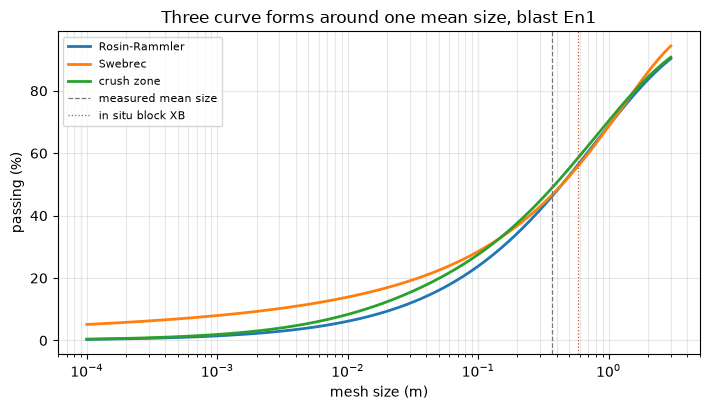

curve,P20 (m),P50 (m),P80 (m)
Rosin-Rammler,0.0732,0.4399,1.6679
Swebrec,0.0347,0.4398,1.5666
crush zone,0.0507,0.3895,1.5845


In [6]:
# The three curves on one axis, with the measured mean size and the in situ block
curves = {"Rosin-Rammler": rosin, "Swebrec": swebrec, "crush zone": crushed}
fig, ax = plt.subplots(figsize=(7.2, 4.2))
for name, curve in curves.items():
    ax.plot(curve.sizes_m, [100 * p for p in curve.passing], lw=2, label=name)
ax.axvline(blast.x50_m, color="#777", lw=0.9, ls="--", label="measured mean size")
ax.axvline(blast.XB_m, color="#c05621", lw=0.9, ls=":", label="in situ block XB")
ax.set_xscale("log")
ax.set_xlabel("mesh size (m)")
ax.set_ylabel("passing (%)")
ax.set_title(f"Three curve forms around one mean size, blast {blast_id}")
ax.legend(fontsize=8)
ax.grid(alpha=0.3, which="both")
fig.tight_layout()
plt.show()
rows = [(name, *[f"{curve.percentile_m(f):.4f}" for f in (0.2, 0.5, 0.8)]) for name, curve in curves.items()]
show_table(["curve", "P20 (m)", "P50 (m)", "P80 (m)"], rows)

The three curves coincide to within a few percentage points above about 0.1 m and part company below it: Swebrec has the most fines, the crush-zone blend sits between it and Rosin-Rammler. For this blast the P20 is 0.0732 m, 0.0347 m and 0.0507 m, the P50 is 0.4399 m, 0.4398 m and 0.3895 m, and the P80 is 1.6679 m, 1.5666 m and 1.5845 m. The figure shows how the forms differ in shape, not which one is accurate: the only measurement is that one mean size, and three curves that agree on it cannot be ranked by it.

### Step 6: the same comparison on 91 blasts

One blast can be an exception, so the cell repeats the comparison on every blast with a geometry through the engine's curve arms, and expresses the P20 and the P80 as ratios to each blast's own mean size so that blasts of different scale can share one axis.

curve,median P20 / x50,median P80 / x50
Rosin-Rammler,0.303,2.428
Swebrec,0.072,3.724
crush zone,0.256,2.544


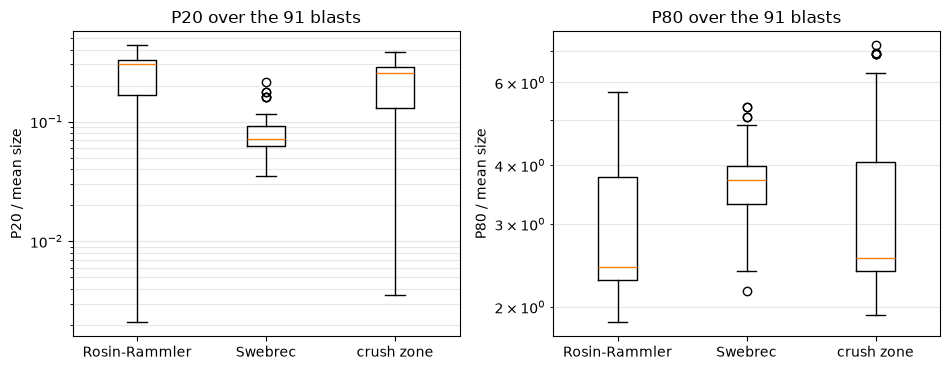

In [7]:
# The same three forms on every blast with a geometry, as ratios to each blast's own mean size
arms = {"Rosin-Rammler": bf.KuzRam(), "Swebrec": bf.Swebrec(), "crush zone": bf.CrushZone()}
with_geometry = [b for b in train if bf.has_absolute_geometry(b)]
ratios = {}
for name, arm in arms.items():
    curves_all = [arm.distribution(b) for b in with_geometry]
    ratios[name] = {
        "P20": np.array([c.percentile_m(0.2) / c.x50_m for c in curves_all]),
        "P80": np.array([c.percentile_m(0.8) / c.x50_m for c in curves_all]),
    }
rows = [(name, f"{np.median(r['P20']):.3f}", f"{np.median(r['P80']):.3f}") for name, r in ratios.items()]
show_table(["curve", "median P20 / x50", "median P80 / x50"], rows)

fig, axes = plt.subplots(1, 2, figsize=(9.6, 3.8))
for ax, key in zip(axes, ("P20", "P80")):
    ax.boxplot([r[key] for r in ratios.values()], tick_labels=list(ratios), showfliers=True)
    ax.set_yscale("log")
    ax.set_ylabel(f"{key} / mean size")
    ax.set_title(f"{key} over the 91 blasts")
    ax.grid(alpha=0.3, axis="y", which="both")
fig.tight_layout()
plt.show()

The single blast was misleading about the P80. Across the 91 blasts the median P20 over the mean size is 0.303 for Rosin-Rammler, 0.072 for Swebrec and 0.256 for the crush zone, so Swebrec's extra fines hold in general. But the median P80 over the mean size is 2.428, 3.724 and 2.544, so Swebrec has the coarsest tail for a typical blast, the reverse of what the Enusa blast showed, because that blast has a low uniformity index and so a wide Rosin-Rammler curve. The Swebrec boxes are narrow because that form ignores the index, and the long Rosin-Rammler whiskers come from the blasts with the lowest indices; for those the P80 is read at the 3 m end of the grid, as the previous notebook showed.

### Step 7: the undulation parameter

The undulation `b` has no published fit on this corpus, so the engine's default is a starting value. The cell sweeps it from 1 to 4 with the mean size and `x_max` unchanged. The left panel shows the curves, the right one the P20 and the P80 against `b` with Rosin-Rammler's values as dotted lines.

b,P20 (m),P50 (m),P80 (m)
1.0,0.0002,0.4398,2.9561
1.5,0.0093,0.4398,2.0359
2.0,0.0347,0.4398,1.5666
3.0,0.0989,0.4398,1.1262
4.0,0.1536,0.4398,0.9258


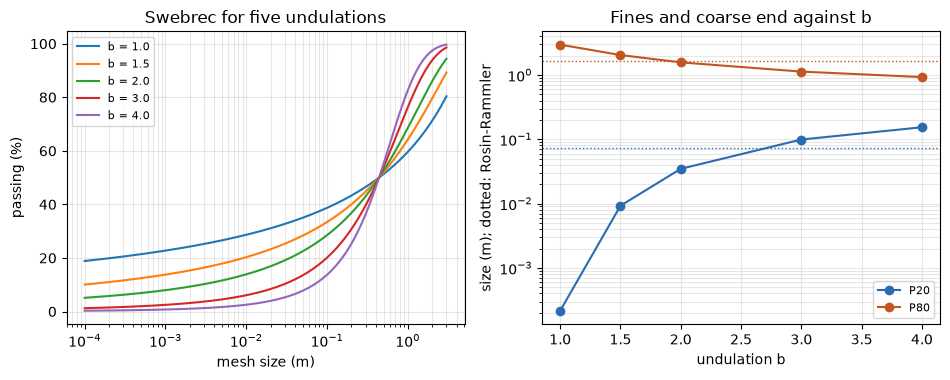

In [8]:
# Scale the undulation b and read the fines and the coarse end, mean size fixed
values = [1.0, 1.5, 2.0, 3.0, 4.0]
family = {b: bf.swebrec(x50, x_max, b) for b in values}
rows = [(b, *[f"{c.percentile_m(f):.4f}" for f in (0.2, 0.5, 0.8)]) for b, c in family.items()]
show_table(["b", "P20 (m)", "P50 (m)", "P80 (m)"], rows)

fig, (left, right) = plt.subplots(1, 2, figsize=(9.6, 3.9))
for b, curve in family.items():
    left.plot(curve.sizes_m, [100 * p for p in curve.passing], label=f"b = {b}")
left.set_xscale("log")
left.set_xlabel("mesh size (m)")
left.set_ylabel("passing (%)")
left.set_title("Swebrec for five undulations")
left.legend(fontsize=8)
left.grid(alpha=0.3, which="both")
for fraction, color in ((0.2, "#2b6cb0"), (0.8, "#c05621")):
    sizes = [family[b].percentile_m(fraction) for b in values]
    right.plot(values, sizes, "o-", color=color, label=f"P{int(fraction * 100)}")
    right.axhline(rosin.percentile_m(fraction), color=color, ls=":", lw=1)
right.set_yscale("log")
right.set_xlabel("undulation b")
right.set_ylabel("size (m); dotted: Rosin-Rammler")
right.set_title("Fines and coarse end against b")
right.legend(fontsize=8)
right.grid(alpha=0.3, which="both")
fig.tight_layout()
plt.show()

With the mean size fixed at 0.4399 m, the undulation moves the two ends in opposite directions. From `b` = 1.0 to `b` = 4.0 the P20 rises from 0.0002 m to 0.1536 m, a change of three orders of magnitude, and the P80 falls from 2.9561 m to 0.9258 m. The default `b` = 2.0 gives 0.0347 m and 1.5666 m, and the dotted Rosin-Rammler lines are crossed between `b` = 2.0 and `b` = 3.0 for the P20 and between `b` = 1.5 and `b` = 2.0 for the P80. The right panel shows that no single `b` matches Rosin-Rammler at both ends, and it does not show which `b` fits this rock: the corpus has nothing to fit it with, which is why the engine treats it as an input to set.

### Step 8: the cap on one blast

`cap_at_in_situ_block` clamps a curve to 1 from the block size up. The cell applies it to the three curves of this blast, tabulates the P80 before and after with the mass each curve had above the block, and draws the curves before (dashed) and after (solid).

curve,P80 uncapped (m),P80 capped (m),mass above XB
Rosin-Rammler,1.668,0.575,43.8%
Swebrec,1.567,0.575,44.3%
crush zone,1.585,0.575,41.6%


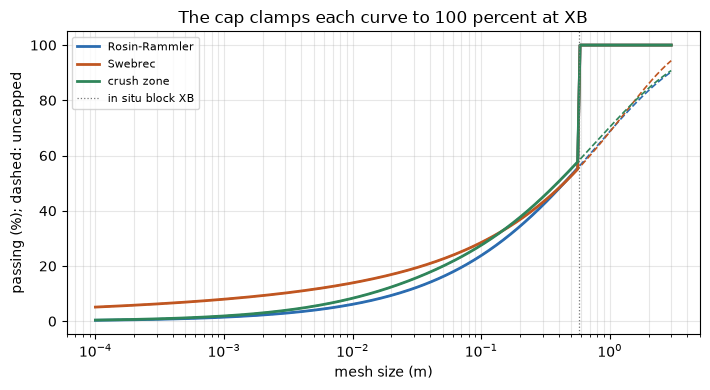

In [9]:
# Cap each curve at the in situ block of this blast: the curve before and after
capped = {name: bf.cap_at_in_situ_block(curve, blast.XB_m) for name, curve in curves.items()}
rows = []
for name, curve in curves.items():
    above = 1 - curve.passing_at(blast.XB_m)
    rows.append((name, f"{curve.percentile_m(0.8):.3f}", f"{capped[name].percentile_m(0.8):.3f}", f"{above:.1%}"))
show_table(["curve", "P80 uncapped (m)", "P80 capped (m)", "mass above XB"], rows)

fig, ax = plt.subplots(figsize=(7.2, 4.0))
for (name, curve), color in zip(curves.items(), ("#2b6cb0", "#c05621", "#2f855a")):
    ax.plot(curve.sizes_m, [100 * p for p in curve.passing], color=color, ls="--", lw=1.2)
    ax.plot(capped[name].sizes_m, [100 * p for p in capped[name].passing], color=color, lw=2, label=name)
ax.axvline(blast.XB_m, color="#777", lw=0.9, ls=":", label="in situ block XB")
ax.set_xscale("log")
ax.set_xlabel("mesh size (m)")
ax.set_ylabel("passing (%); dashed: uncapped")
ax.set_title("The cap clamps each curve to 100 percent at XB")
ax.legend(fontsize=8)
ax.grid(alpha=0.3, which="both")
fig.tight_layout()
plt.show()

Before the cap, the three curves place 43.8, 44.3 and 41.6 percent of the mass above the 0.58 m block, which is impossible for a blast that breaks blocks; after it, the three curves are identical above the block and the P80 of all three is 0.575 m, the grid size just under the block. The cap leaves everything below the block unchanged, so the fines and the P50 of this blast are as in step 5. The figure shows the cap as a hard step to 100 percent at the block size, a modelling choice that assigns the oversize to unbroken blocks rather than to the fines, and it does not show whether the blocks really stay whole.

### Step 9: the cap on 91 blasts

Whether the cap matters depends on how often a curve puts mass above its block. The cell measures that share for each form on every blast, and lists the blasts whose classical mean size already exceeds their block, where the cap acts on the mean and not only on the tail.

curve,median mass above XB,maximum
Rosin-Rammler,10.3%,52.0%
Swebrec,21.1%,53.8%
crush zone,9.7%,49.4%


blasts whose classical mean size exceeds their block: ['Rc1', 'Rc2', 'Rc3']


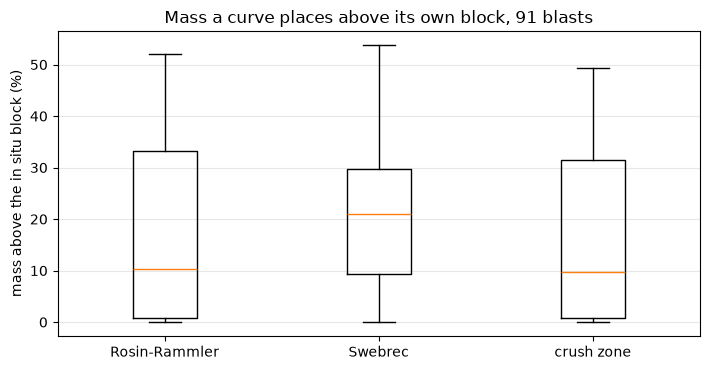

In [10]:
# How much mass each uncapped curve puts above the block, on every blast, and where the cap binds on the mean
share_above = {
    name: np.array([1 - arm.distribution(b).passing_at(b.XB_m) for b in with_geometry])
    for name, arm in arms.items()
}
plain = bf.Kuznetsov()
binding = [b.blast_id for b in with_geometry if plain.predict_one(b).x50_m > b.XB_m]
rows = [(name, f"{np.median(v):.1%}", f"{v.max():.1%}") for name, v in share_above.items()]
show_table(["curve", "median mass above XB", "maximum"], rows)
print("blasts whose classical mean size exceeds their block:", binding)

fig, ax = plt.subplots(figsize=(7.2, 3.8))
ax.boxplot([100 * v for v in share_above.values()], tick_labels=list(share_above), showfliers=True)
ax.set_ylabel("mass above the in situ block (%)")
ax.set_title("Mass a curve places above its own block, 91 blasts")
ax.grid(alpha=0.3, axis="y")
fig.tight_layout()
plt.show()

Over the 91 blasts the median share of mass above the block is 10.3 percent for Rosin-Rammler, 21.1 percent for Swebrec and 9.7 percent for the crush zone, with maxima of 52.0, 53.8 and 49.4 percent. The Enusa blast, with 43.8 percent, is therefore a high case, not a typical one, and Swebrec's coarse tail makes the cap bind hardest on it. Only three blasts, Rc1, Rc2 and Rc3, have a classical mean size above their block, so for the other 88 the cap acts on the tail and never on the mean. The figure shows how much mass the forms disagree about, not how much of it is real.

### Step 10: does the cap improve the one measured quantity?

The mean size is the only size the corpus measures, so it is the only place the cap can be tested. The cell scores the classical mean size and the capped one against the 91 measured values with the engine's `score`, and lists the blasts where the cap changes the prediction.

In [11]:
# The one measured quantity: score the mean size with and without the cap on the 91 blasts
cap_arm = bf.InSituCap(plain)
uncapped_predictions = [plain.predict_one(b) for b in with_geometry]
capped_predictions = [cap_arm.predict_one(b) for b in with_geometry]
scores = {
    "classical mean size": bf.score(with_geometry, uncapped_predictions),
    "classical, capped at the block": bf.score(with_geometry, capped_predictions),
}
rows = [(name, f"{s.r2_identity:.4f}", f"{s.rmse_m:.4f}") for name, s in scores.items()]
show_table(["mean size from", "r2_identity", "RMSE (m)"], rows)
changed = [(b.blast_id, b.site) for b, p in zip(with_geometry, capped_predictions) if p.detail["cap_binds"]]
print("blasts where the cap changes the mean size:", changed)

mean size from,r2_identity,RMSE (m)
classical mean size,0.3112,0.1528
"classical, capped at the block",0.3523,0.1482


blasts where the cap changes the mean size: [('Rc1', 'Reocin'), ('Rc2', 'Reocin'), ('Rc3', 'Reocin')]


The cap changes the prediction on exactly the three blasts Rc1, Rc2 and Rc3, and on the 91 blasts it lifts the variance explained about the identity line from 0.3112 to 0.3523 and lowers the root-mean-square error from 0.1528 m to 0.1482 m. This is the only place where a curve choice meets a measurement, and the cap passes the test: it moves the three blasts whose classical mean size exceeds the measured block toward the measured values. The result rests on three blasts, all from the Reocin campaign, and the classical rock factors were derived from published predictions of the same corpus, so the improvement is an indication and not a validated gain.

## Results

**Answer:** the three forms agree in the middle and disagree at the tails, and the cap changes the tail of every curve and the mean of three blasts. For the Enusa blast the P50 is 0.4399 m, 0.4398 m and 0.3895 m, but the P20 is 0.0732 m, 0.0347 m and 0.0507 m. Across the 91 blasts the median P20 over the mean size is 0.303, 0.072 and 0.256, and the median P80 over the mean size is 2.428, 3.724 and 2.544, so Swebrec has both the most fines and the coarsest tail for a typical blast. Its undulation alone moves the P20 from 0.0002 m to 0.1536 m. The cap removes 43.8, 44.3 and 41.6 percent of the mass that the three curves put above the Enusa block, and on the 91 blasts it acts on the mean of only Rc1, Rc2 and Rc3, which raises the variance explained from 0.3112 to 0.3523.

**What this does not show.** None of these curves was compared with a measured size distribution, and the crush-zone constants are not published values, so the differences above are differences between model forms, not differences in accuracy. The Swebrec undulation has no fit on this corpus, and the cap's gain rests on three blasts. That is why this topic has no state-of-the-art notebook: with only the mean size measured, there is nothing to rank the forms against.

## Summary

- Three curve forms share one mean size and differ in the tails: Swebrec has the most fines and, for a typical blast, the coarsest P80.
- The Swebrec undulation moves the fines by three orders of magnitude and the crush-zone constants are not published values; neither can be fitted on this corpus.
- The cap at the in situ block removes oversize that cannot exist and improves the mean size on the three blasts where it acts.
- Next: topic 04 turns from what a model predicts to how a prediction is judged.

## References

- Ouchterlony 2005, https://doi.org/10.1179/037178405x44539 (the Swebrec function)
- Amoako, Jha and Zhong 2022, https://doi.org/10.3390/mining2020013 (Eqs. 5, 10 and 11 and the description of the crush-zone mechanism)
- Babaeian et al. 2019, https://doi.org/10.1016/j.jrmge.2018.11.006 (the bauxite counter-example for Swebrec)
- Hudaverdi, Kulatilake and Kuzu 2010, https://doi.org/10.1002/nag.957 (the corpus)
- `blastfrag` 0.4.0, the engine, on PyPI: https://pypi.org/project/blastfrag/